# 02 — Data Preparation
**Tahap lifecycle:** [L] Learning Problem · **Minggu 2** · Bab 5.1–5.6

**Tujuan:** data bersih, siap dipakai, dan terbagi dengan benar **tanpa kebocoran informasi (leakage)**.

**Urutan eksekusi (berbeda sedikit dari urutan bab laporan, demi mencegah leakage):**
1. 5.1 Cleaning → 2. 5.2 Feature engineering *(transformasi tanpa parameter yang dipelajari dari data; hanya memakai hari ≤ t)*
3. **5.4 Splitting** → 4. 5.3 Transformasi & seleksi fitur *(parameter di-`fit` hanya pada train)* → 5. 5.5 Balancing *(hanya train)* → 6. simpan artefak → 7. verifikasi checklist → 8. 5.6 ringkasan.

Setiap langkah diawali alasan tertulis (**Apa – Mengapa – Bagaimana**).

In [1]:
import sys, json, hashlib, warnings
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
import prep

warnings.filterwarnings("ignore")
SEED = prep.SEED
np.random.seed(SEED)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

RAW = prep.find_raw_dir()
OUT = Path("../data/processed"); OUT.mkdir(parents=True, exist_ok=True)
MODELS = Path("../models"); MODELS.mkdir(exist_ok=True)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
SUMMARY = {}   # dikumpulkan untuk laporan Bab 5
print(f"SEED={SEED} | radius={prep.RADIUS_KM} km | horizon=H+{prep.HORIZON_DAYS}")

SEED=42 | radius=25 km | horizon=H+1


## 5.1 Data Cleaning

### (a) Parsing tanggal & penyelarasan zona waktu
- **Apa:** kolom `date` cuaca (`2019-01-01 00:00:00+00:00`) dan `acq_date` VIIRS (`2018-04-01`) diubah ke `datetime` tanpa zona waktu (tanggal UTC).
- **Mengapa:** kunci penggabungan (lokasi, tanggal) harus bertipe sama; kedua sumber sama-sama berbasis hari UTC sehingga tidak ada pergeseran tanggal.
- **Bagaimana:** `pd.to_datetime(..., utc=True).dt.tz_localize(None).dt.normalize()`; lokasi diberi ID `L1–L6` (urut bujur).

In [2]:
w = prep.load_weather(RAW / "data_cuaca_semua_lokasi.csv")
v = prep.load_viirs(RAW / "viirs-jpss1_2018_2025_Indonesia.csv")
locs = prep.location_table(w)
v_start, v_end = v["acq_date"].min(), v["acq_date"].max()
print("Cuaca :", w["date"].min().date(), "->", w["date"].max().date(), "| baris", len(w))
print("VIIRS :", v_start.date(), "->", v_end.date(), "| baris", f"{len(v):,}")
display(locs)

Cuaca : 2019-01-01 -> 2026-11-10 | baris 17226
VIIRS : 2018-04-01 -> 2024-12-31 | baris 1,213,145


,loc_id,latitude,longitude
0,L1,-1.722320,103.714287
1,L2,-3.268893,105.266556
2,L3,-3.760984,105.718925
3,L4,-1.722320,110.214294
4,L5,-2.776801,112.771080
5,L6,-2.284710,114.225235


### (b) Verifikasi missing value & duplikat
- **Apa/Mengapa:** EDA (notebook 01) menunjukkan 0 missing dan 0 duplikat; di sini diverifikasi otomatis agar pipeline gagal-keras bila data diganti dengan versi yang bermasalah.
- **Bagaimana:** `assert`. Tidak perlu imputasi (imputasi pada deret waktu justru berisiko menyuntikkan informasi dari masa depan).

In [3]:
assert w.isna().sum().sum() == 0 and v.isna().sum().sum() == 0
assert not w.duplicated(["loc_id", "date"]).any() and not v.duplicated().any()
assert w.groupby("loc_id")["date"].nunique().nunique() == 1   # tiap lokasi punya jumlah hari sama
print("OK: tidak ada missing value, tidak ada duplikat, kalender harian cuaca lengkap.")

OK: tidak ada missing value, tidak ada duplikat, kalender harian cuaca lengkap.


### (c) Menyaring noise VIIRS
- **Apa:** hanya deteksi **kebakaran vegetasi** (`type == 0`) dengan `confidence != 'l'` yang dihitung sebagai hotspot.
- **Mengapa:** `type` 1–3 = gunung api aktif, sumber statis (mis. flare industri), dan lepas pantai — bukan karhutla; confidence *low* memuat banyak positif palsu (sun-glint, dll.). Memasukkannya membuat label berisik.
- **Bagaimana:** `prep.filter_viirs`. Kolom konstan (`satellite`, `instrument`, `version`) dan `source_year` (penanda berkas) tidak dipakai karena VIIRS hanya diagregasi menjadi label/riwayat hotspot.

In [4]:
vf = prep.filter_viirs(v)
funnel_v = pd.DataFrame({
    "tahap": ["Seluruh deteksi VIIRS", "type == 0 (kebakaran vegetasi)", "confidence != low"],
    "n": [len(v), int((v["type"] == 0).sum()), len(vf)],
})
funnel_v["% dari awal"] = (100 * funnel_v["n"] / len(v)).round(1)
display(funnel_v)
SUMMARY["viirs_funnel"] = funnel_v.to_dict("records")

,tahap,n,% dari awal
0,Seluruh deteksi VIIRS,1213145,100.0
1,type == 0 (kebakaran vegetasi),1121686,92.5
2,confidence != low,1038721,85.6


### (d) Hari tanpa data satelit (gap)
- **Apa:** 7 hari memiliki **0 hotspot di seluruh Indonesia** (median normal ≈ 159/hari) — hampir pasti data satelit hilang, bukan "tidak ada api".
- **Mengapa:** jika dibiarkan sebagai 0 akan menjadi **label negatif palsu** dan merusak fitur riwayat.
- **Bagaimana:** hitungan hotspot pada hari tsb dijadikan `NaN`; baris yang labelnya jatuh pada hari gap, atau yang hari-t-nya gap, dibuang (lihat funnel baris di bawah).

In [5]:
gaps = prep.gap_days(v, v_start, v_end)
print("Hari gap:", [d.strftime("%Y-%m-%d") for d in gaps])

Hari gap: ['2023-07-19', '2023-07-20', '2023-07-21', '2023-07-22', '2023-09-30', '2024-02-04', '2024-02-05']


### (e) Outlier
- **Apa:** outlier IQR ada pada presipitasi (3,6%), VPD (3,8%), suhu (3,3%), dll. **Tidak dihapus.**
- **Mengapa:** semuanya valid secara fisik (hujan lebat, hari sangat kering/panas) — justru kondisi ekstrem inilah yang relevan untuk kebakaran; FRP ekstrem (hingga 1.840 MW) adalah kebakaran besar yang nyata.
- **Bagaimana:** kemiringan ditangani lewat `log1p` (5.3), bukan dengan membuang data.

In [6]:
for c in ["precipitation_sum", "vapour_pressure_deficit_max"]:
    print(f"{c:32s} skew awal = {w[c].skew():5.2f} | setelah log1p = {np.log1p(w[c]).skew():5.2f}")

precipitation_sum                skew awal =  2.34 | setelah log1p = -0.13
vapour_pressure_deficit_max      skew awal =  1.05 | setelah log1p =  0.14


### (f) Agregasi hotspot per (lokasi, hari) & penggabungan dengan cuaca
- **Apa:** untuk tiap titik cuaca, hitung jumlah hotspot dan total FRP dalam radius 25 km per hari (jarak haversine), lalu gabungkan ke tabel cuaca.
- **Mengapa:** cuaca bersifat titik-harian, sedangkan VIIRS bersifat kejadian-spasial; radius 25 km menghasilkan keseimbangan kelas yang wajar (≈10% positif) dan lingkaran 6 titik tidak saling tumpang tindih (jarak minimum titik ≈74 km).
- **Bagaimana:** `prep.daily_hotspots` → grid harian lengkap (hari tanpa deteksi = 0, hari gap = NaN) → `merge` pada (`loc_id`, `date`).

In [7]:
hs = prep.daily_hotspots(vf, locs, v_start, v_end, prep.RADIUS_KM)
hs = prep.add_hotspot_history(hs, gaps)          # fitur riwayat (5.2) dihitung pada grid VIIRS penuh sejak 2018-04
df = w.merge(hs, on=["loc_id", "date"], how="left")
print("Setelah merge:", df.shape, "| hotspot terhitung (total):", int(df["hs_count"].sum()))
df[["loc_id", "date", "hs_count", "hs_frp_sum"]].query("hs_count > 0").head(5)

Setelah merge: (17226, 18) | hotspot terhitung (total): 42720


,loc_id,date,hs_count,hs_frp_sum
5,L1,2019-01-06,1.0,0.75
7,L1,2019-01-08,1.0,0.76
8,L1,2019-01-09,1.0,0.60
10,L1,2019-01-11,2.0,0.78
12,L1,2019-01-13,2.0,1.46


## 5.2 Feature Engineering

Semua fitur dihitung **hanya dari hari ≤ t** (jendela mundur) per lokasi. Target = ada hotspot pada hari **t+1**.

| Grup | Fitur | Definisi | Alasan |
|---|---|---|---|
| Cuaca mentah (8) | presipitasi, suhu maks, ET0, RH min, angin maks, VPD maks, kelembapan tanah 0–7 & 7–28 cm | nilai hari t | kondisi langsung bahan bakar & atmosfer |
| Akumulasi hujan | `precip_sum_{3,7,14,30}d` | jumlah hujan jendela mundur | kekeringan itu kumulatif; satu hari tanpa hujan belum berarti kering |
| Spell kering | `dry_days_consec` | hari berturut-turut hujan < 1 mm (maks 90) | lamanya kekeringan |
| Rata-rata 7 hari | suhu, RH, VPD, angin | rolling mean 7 hari | meredam noise harian |
| Tanah | `soil_0_7_mean_7d`, `soil_7_28_mean_14d`, `soil_0_7_delta_7d` | rolling mean & selisih 7 hari | tren pengeringan tanah/gambut |
| Neraca air | `water_deficit_14d` | ΣET0 14 hari − Σhujan 14 hari | defisit air fisik |
| Musiman | `doy_sin`, `doy_cos` | sin/cos hari-dalam-tahun | musim api siklik, kontinu di pergantian tahun |
| Riwayat hotspot | `hs_count`, `hs_count_7d`, `hs_count_30d`, `hs_frp_sum_7d`, `hs_days_since_last` | hitungan/FRP/umur api terakhir | persistensi api — dipisah sebagai grup agar dapat di-*ablation* di Minggu 3 |
| Lokasi | one-hot `loc_id` | L1–L6 | tingkat dasar tiap lokasi berbeda (7–15%) |

In [8]:
df = prep.add_weather_features(df)
df = prep.add_target(df, gaps, v_end)
df["split"] = prep.assign_split(df["target_date"])
feat_all = prep.RAW_WEATHER_COLS + prep.WEATHER_ENGINEERED + prep.HOTSPOT_HISTORY + prep.SEASONAL
print(len(feat_all), "fitur numerik + loc_id (one-hot) sebelum seleksi")

28 fitur numerik + loc_id (one-hot) sebelum seleksi


### Funnel baris: dari 17.226 baris cuaca ke data berlabel
- **Mengapa:** setiap baris yang dibuang harus punya alasan eksplisit.

In [9]:
steps, cur = [], df.copy()
steps.append(("Baris cuaca awal (6 lokasi × 2.871 hari)", len(cur)))
cur = cur[cur["target_date"] <= v_end];          steps.append((f"Buang hari tanpa label (target_date > {v_end.date()}; cuaca 2025–2026 tidak punya VIIRS)", len(cur)))
cur = cur[~cur["target_date"].isin(gaps)];        steps.append(("Buang baris yang labelnya jatuh pada hari gap satelit", len(cur)))
cur = cur[~cur["date"].isin(gaps)];               steps.append(("Buang baris dengan hari-t gap (hs_count tidak valid)", len(cur)))
cur = cur.dropna(subset=feat_all);                steps.append(("Buang warm-up jendela rolling 30 hari (29 hari pertama per lokasi)", len(cur)))
funnel_r = pd.DataFrame(steps, columns=["tahap", "n_baris"])
funnel_r["dibuang"] = (-funnel_r["n_baris"].diff()).fillna(0).astype(int)
display(funnel_r)
assert cur["fire_next_day"].notna().all()
lab = cur.copy(); lab["fire_next_day"] = lab["fire_next_day"].astype(int)
SUMMARY["row_funnel"] = funnel_r.to_dict("records")
print("Data berlabel:", lab.shape)

,tahap,n_baris,dibuang
0,Baris cuaca awal (6 lokasi × 2.871 hari),17226,0
1,Buang hari tanpa label (target_date > 2024-12-...,13146,4080
2,Buang baris yang labelnya jatuh pada hari gap ...,13104,42
3,Buang baris dengan hari-t gap (hs_count tidak ...,13086,18
4,Buang warm-up jendela rolling 30 hari (29 hari...,12912,174


Data berlabel: (12912, 37)


### Uji kausalitas fitur (anti-leakage)
- **Apa:** membuktikan bahwa fitur pada hari t **tidak berubah** bila data setelah t dihapus.
- **Mengapa:** kesalahan jendela (mis. `center=True`, atau `shift` arah salah) adalah sumber leakage yang paling umum pada fitur deret waktu.
- **Bagaimana:** hitung fitur pada data yang dipotong di 2023-06-30 vs data penuh, bandingkan seluruh baris ≤ tanggal itu.

In [10]:
cut = pd.Timestamp("2023-06-30")
# fitur cuaca
f_cut  = prep.add_weather_features(w[w["date"] <= cut]).sort_values(["loc_id", "date"]).reset_index(drop=True)
f_full = prep.add_weather_features(w).query("date <= @cut").sort_values(["loc_id", "date"]).reset_index(drop=True)
cols_w = prep.WEATHER_ENGINEERED + prep.SEASONAL
ok_w = np.allclose(f_cut[cols_w].values, f_full[cols_w].values, equal_nan=True)
# fitur riwayat hotspot
hs_raw = prep.daily_hotspots(vf, locs, v_start, v_end, prep.RADIUS_KM)
h_cut  = prep.add_hotspot_history(hs_raw[hs_raw["date"] <= cut], gaps).sort_values(["loc_id", "date"]).reset_index(drop=True)
h_full = prep.add_hotspot_history(hs_raw, gaps).query("date <= @cut").sort_values(["loc_id", "date"]).reset_index(drop=True)
cols_h = prep.HOTSPOT_HISTORY[1:]
ok_h = np.allclose(h_cut[cols_h].values, h_full[cols_h].values, equal_nan=True)
# label = hotspot hari t+1
chk = lab.merge(hs[["loc_id", "date", "hs_count"]].rename(columns={"date": "target_date", "hs_count": "hs_next"}), on=["loc_id", "target_date"])
ok_t = ((chk["hs_next"] > 0).astype(int) == chk["fire_next_day"]).all()
print(f"fitur cuaca kausal: {ok_w} | fitur riwayat hotspot kausal: {ok_h} | label == hotspot hari t+1: {ok_t}")
assert ok_w and ok_h and ok_t
SUMMARY["causality_checks_passed"] = True

fitur cuaca kausal: True | fitur riwayat hotspot kausal: True | label == hotspot hari t+1: True


## 5.4 Data Splitting

- **Apa:** split **kronologis berdasarkan tanggal target** — train: target 2019-01-31…2022-12-31, validasi: 2023, test: 2024. `random_state = 42` dipakai di seluruh komponen acak (diagnostik di bawah, model berikutnya).
- **Mengapa bukan *stratified random*?** Data adalah deret waktu spasial: hari-hari bersebelahan sangat berautokorelasi dan fitur rolling saling tumpang tindih, sehingga split acak menaruh "tetangga" yang hampir identik di train dan validasi. Skenario nyata juga selalu *memprediksi masa depan dari masa lalu*. Stratifikasi tidak dapat dipenuhi bersamaan dengan urutan waktu; sebagai gantinya proporsi kelas tiap split **dilaporkan**, dan pembobotan kelas dihitung dari train (5.5).
- **Pembagian:** 2019–2022 memuat satu tahun api besar (2019) dan tiga tahun basah; 2023 (El Niño, api besar) menjadi validasi; 2024 (tahun terakhir) menjadi test yang **dikunci** hingga Minggu 6.
- **Bagaimana:** `prep.assign_split` (batas tanggal ada di `src/prep.py`).

In [11]:
tr, va, te = (lab[lab["split"] == s].copy() for s in ["train", "val", "test"])
assert tr["target_date"].max() < va["target_date"].min() and va["target_date"].max() < te["target_date"].min()

rows = []
for name, d in [("train", tr), ("val", va), ("test", te)]:
    rows.append(dict(split=name, n_sampel=len(d), persen=round(100 * len(d) / len(lab), 1),
                     target_date_min=d["target_date"].min().date(), target_date_max=d["target_date"].max().date(),
                     n_positif=int(d["fire_next_day"].sum()) if name != "test" else "dikunci",
                     persen_positif=round(100 * d["fire_next_day"].mean(), 1) if name != "test" else "dikunci"))
split_tbl = pd.DataFrame(rows)
display(split_tbl)
print("Sampel per lokasi:"); display(lab.pivot_table(index="loc_id", columns="split", values="fire_next_day", aggfunc="size")[["train", "val", "test"]])
SUMMARY["split_table"] = json.loads(split_tbl.to_json(orient="records"))

,split,n_sampel,persen,target_date_min,target_date_max,n_positif,persen_positif
0,train,8586,66.5,2019-01-31,2022-12-31,858,10.0
1,val,2148,16.6,2023-01-01,2023-12-31,444,20.7
2,test,2178,16.9,2024-01-01,2024-12-31,dikunci,dikunci


Sampel per lokasi:


split,train,val,test
loc_id,,,
L1,1431,358,363
L2,1431,358,363
L3,1431,358,363
L4,1431,358,363
L5,1431,358,363
L6,1431,358,363


### Diagnostik: apakah split acak benar-benar bocor?
- **Apa/Mengapa:** membandingkan skor validasi Random Forest sederhana pada split acak-stratified vs kronologis, **hanya memakai data train+val** (test tidak dipakai), untuk mengukur seberapa besar split acak menggelembungkan skor.
- **Catatan:** ini diagnostik keputusan desain, **bukan** pemilihan model. Satu kali pengacakan tidak cukup (skor bergantung pada hari mana yang kebetulan masuk set evaluasi), maka diulang 10 seed dengan urutan baris dibakukan. PR-AUC tidak sebanding langsung antar skema karena proporsi positif set evaluasinya berbeda.

In [12]:
dummies = [f"loc_id_{l}" for l in sorted(lab["loc_id"].unique())]
tv = pd.concat([tr, va]).sort_values(["loc_id", "date"]).reset_index(drop=True)   # urutan baku -> hasil deterministik
tv = pd.get_dummies(tv, columns=["loc_id"], dtype=float)
Xc = feat_all + dummies
def rf_scores(a, b):
    m = RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced", random_state=SEED, n_jobs=-1)
    m.fit(a[Xc], a["fire_next_day"]); p = m.predict_proba(b[Xc])[:, 1]
    return roc_auc_score(b["fire_next_day"], p), average_precision_score(b["fire_next_day"], p)

rand = [rf_scores(*train_test_split(tv, test_size=0.2, stratify=tv["fire_next_day"], random_state=SEED + k)) for k in range(10)]
rand = np.array(rand)
r_chrono = rf_scores(tv[tv["split"] == "train"], tv[tv["split"] == "val"])
diag = pd.DataFrame({
    "skema split": ["acak stratified 80/20 (10 seed: 42-51)", "kronologis (train 2019-22 -> val 2023)"],
    "ROC-AUC": [f"{rand[:,0].mean():.3f} ± {rand[:,0].std():.3f} (min {rand[:,0].min():.3f}, maks {rand[:,0].max():.3f})", f"{r_chrono[0]:.3f}"],
    "PR-AUC":  [f"{rand[:,1].mean():.3f} ± {rand[:,1].std():.3f} (min {rand[:,1].min():.3f}, maks {rand[:,1].max():.3f})", f"{r_chrono[1]:.3f}"],
    "proporsi positif di set evaluasi": [f"{tv['fire_next_day'].mean():.1%}", f"{va['fire_next_day'].mean():.1%}"],
})
display(diag)
print("ROC-AUC per seed (acak):", rand[:, 0].round(3).tolist())
print("Skor kronologis berada dalam rentang acak (ROC-AUC):", bool(rand[:, 0].min() <= r_chrono[0] <= rand[:, 0].max()))
SUMMARY["leak_diag"] = diag.to_dict("records"); SUMMARY["leak_diag_seed_auc"] = rand[:, 0].round(4).tolist()

,skema split,ROC-AUC,PR-AUC,proporsi positif di set evaluasi
0,acak stratified 80/20 (10 seed: 42-51),"0.930 ± 0.010 (min 0.915, maks 0.943)","0.784 ± 0.028 (min 0.726, maks 0.825)",12.1%
1,kronologis (train 2019-22 -> val 2023),0.929,0.835,20.7%


ROC-AUC per seed (acak): [0.943, 0.916, 0.915, 0.939, 0.92, 0.935, 0.94, 0.927, 0.933, 0.935]
Skor kronologis berada dalam rentang acak (ROC-AUC): True


**Pembacaan hasil (jujur):** skor split acak berfluktuasi menurut hari mana yang kebetulan masuk set evaluasi (ROC-AUC 0,915–0,943), dan skor kronologis (0,929) berada **di dalam rentang itu**. Jadi pada dataset ini **tidak terbukti** bahwa split acak menggelembungkan skor secara sistematis; keunggulan split kronologis ada pada hal lain:
1. skenario penggunaan sebenarnya adalah memprediksi hari-hari **mendatang**, sehingga estimasi performa harus meniru itu;
2. split acak menghasilkan estimasi yang lebih berisik (simpangan ±0,01 antar seed) dan memberi proporsi positif evaluasi ≈12% yang **menyembunyikan pergeseran distribusi** (validasi 2023 memiliki 20,7% positif);
3. fitur rolling membuat hari bertetangga hampir identik, sehingga risiko kebocoran bersifat struktural walau tidak terukur kuat pada satu model ini.
PR-AUC kedua skema tidak sebanding langsung karena proporsi positif set evaluasinya berbeda.

## 5.3 Data Transformation (semua parameter di-`fit` hanya pada train)

### (a) Seleksi fitur berbasis korelasi — hanya train
- **Apa:** untuk setiap pasangan fitur dengan |Spearman ρ| > 0,97, buang salah satu — yang korelasinya dengan target lebih rendah.
- **Mengapa:** EDA menunjukkan fitur sangat redundan (RH vs VPD 0,99; dua lapisan tanah 0,98). Redundansi membuat koefisien regresi logistik tidak stabil dan memboroskan kapasitas MLP; pohon tidak terpengaruh. Seluruh fitur tetap tersimpan di berkas `*_engineered.csv` untuk ablation.
- **Bagaimana:** korelasi dihitung dari **train saja**.

In [13]:
def corr_prune(df_tr, feats, target, thr=0.97):
    c = df_tr[feats].corr(method="spearman").abs()
    ty = df_tr[feats].apply(lambda s: abs(s.corr(df_tr[target], method="spearman")))
    keep, dropped = set(feats), []
    pairs = sorted([(c.loc[a, b], a, b) for i, a in enumerate(feats) for b in feats[i+1:] if c.loc[a, b] > thr], reverse=True)
    for r, a, b in pairs:
        if a in keep and b in keep:
            d = a if ty[a] < ty[b] else b
            keep.discard(d); dropped.append(dict(dibuang=d, dipertahankan=(b if d == a else a), abs_rho=round(r, 3)))
    return [f for f in feats if f in keep], dropped

selected, dropped = corr_prune(tr, feat_all, "fire_next_day")
display(pd.DataFrame(dropped))
print(f"{len(feat_all)} -> {len(selected)} fitur numerik")

,dibuang,dipertahankan,abs_rho
0,precip_sum_14d,water_deficit_14d,0.996
1,hs_frp_sum_7d,hs_count_7d,0.996
2,vapour_pressure_deficit_max,relative_humidity_2m_min,0.993
3,vpd_max_mean_7d,rh_min_mean_7d,0.990
4,soil_moisture_0_to_7cm_mean,soil_moisture_7_to_28cm_mean,0.978
5,soil_0_7_mean_7d,soil_moisture_7_to_28cm_mean,0.975


28 -> 22 fitur numerik


### (b) `log1p` pada fitur berekor panjang
- **Apa/Mengapa:** presipitasi, akumulasi hujan, hitungan hotspot, dan FRP sangat miring ke kanan (skew 2–10+); `log1p` menstabilkan skala dan menjaga nol tetap nol.
- **Bagaimana:** transformasi deterministik (tanpa parameter) sehingga tidak berpotensi leakage.

### (c) One-hot `loc_id` + StandardScaler + fitur siklik apa adanya
- **Mengapa:** model linear/MLP sensitif skala → standardisasi; `doy_sin/cos` sudah di [-1, 1]; `loc_id` nominal → one-hot (`handle_unknown='ignore'`).
- **Bagaimana:** `ColumnTransformer` di-`fit` pada **train saja**, lalu `transform` untuk validasi & test.

In [14]:
log_cols = [c for c in prep.LOG1P_COLS if c in selected]
num_cols = [c for c in selected if c not in prep.SEASONAL]

def apply_log(d):
    d = d.copy(); d[log_cols] = np.log1p(d[log_cols].clip(lower=0)); return d

pre = ColumnTransformer(
    [("loc", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["loc_id"]),
     ("num", StandardScaler(), num_cols),
     ("cyc", "passthrough", [c for c in selected if c in prep.SEASONAL])],
    verbose_feature_names_out=False).set_output(transform="pandas")

pre.fit(apply_log(tr))                      # <<< FIT HANYA PADA TRAIN
X_tr, X_va, X_te = (pre.transform(apply_log(d)) for d in (tr, va, te))
print("Bentuk X:", X_tr.shape, X_va.shape, X_te.shape)
print("log1p diterapkan pada:", log_cols)
print("\nrata-rata |mean| fitur numerik terstandar: train =", round(X_tr[num_cols].mean().abs().mean(), 3),
      "(≈0 karena di-fit di sini) | val =", round(X_va[num_cols].mean().abs().mean(), 3), "(≠0 karena TIDAK di-fit ulang)")

Bentuk X: (8586, 28) (2148, 28) (2178, 28)
log1p diterapkan pada: ['precipitation_sum', 'precip_sum_3d', 'precip_sum_7d', 'precip_sum_30d', 'hs_count', 'hs_count_7d', 'hs_count_30d']

rata-rata |mean| fitur numerik terstandar: train = 0.0 (≈0 karena di-fit di sini) | val = 0.383 (≠0 karena TIDAK di-fit ulang)


## 5.5 Data Balancing (hanya pada training)

- **Apa:** kelas positif hanya ≈10% di train (rasio ≈ 9:1). Dipakai **class weight** yang dihitung dari train; data validasi/test **tidak** diubah.
- **Mengapa bukan SMOTE/undersampling?** (1) Baris adalah deret waktu dengan fitur rolling — sampel sintetis hasil interpolasi menghasilkan kombinasi hujan/riwayat yang tidak pernah terjadi dan merusak koherensi temporal; fitur one-hot lokasi juga menjadi non-biner. (2) Rasio 9:1 tergolong sedang; class weight + metrik PR-AUC/F1 cukup. (3) Undersampling membuang ≈ 90% hari negatif. SMOTE dicatat sebagai kandidat iterasi di Bab 7.5 bila recall kelas positif rendah.
- **Bagaimana:** `weight_c = n / (2 · n_c)`; juga disimpan `scale_pos_weight = n_neg / n_pos` untuk XGBoost/LightGBM.

{
 "0": 0.5555,
 "1": 5.0035,
 "scale_pos_weight": 9.007,
 "n_train": 8586,
 "n_neg": 7728,
 "n_pos": 858,
 "dihitung_dari": "train saja"
}


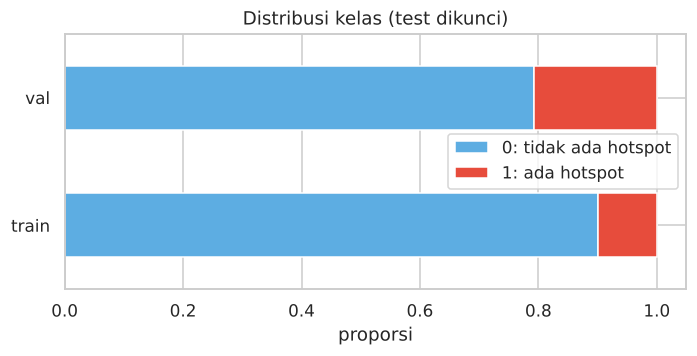

In [15]:
y_tr, y_va, y_te = tr["fire_next_day"], va["fire_next_day"], te["fire_next_day"]
n, n0, n1 = len(y_tr), int((y_tr == 0).sum()), int((y_tr == 1).sum())
class_weights = {"0": n / (2 * n0), "1": n / (2 * n1), "scale_pos_weight": n0 / n1,
                 "n_train": n, "n_neg": n0, "n_pos": n1, "dihitung_dari": "train saja"}
print(json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in class_weights.items()}, indent=1))
SUMMARY["class_weights"] = class_weights

fig, ax = plt.subplots(figsize=(6.5, 3.4))
yy = pd.DataFrame({"train": [n0 / n, n1 / n], "val": [(y_va == 0).mean(), (y_va == 1).mean()]}, index=["0: tidak ada hotspot", "1: ada hotspot"])
yy.T.plot.barh(stacked=True, ax=ax, color=["#5dade2", "#e74c3c"]); ax.set_xlabel("proporsi"); ax.set_title("Distribusi kelas (test dikunci)")
fig.tight_layout(); fig.savefig(FIG / "fig07_distribusi_kelas_split.png"); plt.show()

## Menyimpan artefak
- `*_model.csv` : fitur siap model (log1p + scaling + one-hot) + target + kolom meta
- `*_engineered.csv` : fitur mentah hasil rekayasa (belum diskalakan, seluruh fitur) untuk model pohon / ablation
- `models/preprocessor.joblib` : transformer yang di-fit pada train
- `feature_lists.json`, `class_weights.json`, `split_summary.csv`, `test_checksums.json` (sidik jari SHA-256 test set agar bisa dibuktikan tidak berubah sampai Minggu 6)

In [16]:
meta_cols = ["loc_id", "latitude", "longitude", "date", "target_date"]
def save_split(name, d, X):
    m = pd.concat([d[meta_cols].reset_index(drop=True), X.reset_index(drop=True), d[["fire_next_day"]].reset_index(drop=True)], axis=1)
    m.to_csv(OUT / f"{name}_model.csv", index=False)
    e = d[meta_cols + feat_all + ["fire_next_day"]].reset_index(drop=True)
    e.to_csv(OUT / f"{name}_engineered.csv", index=False)

for name, d, X in [("train", tr, X_tr), ("val", va, X_va), ("test", te, X_te)]:
    save_split(name, d, X)

joblib.dump(pre, MODELS / "preprocessor.joblib")
groups = {"weather_raw": prep.RAW_WEATHER_COLS, "weather_engineered": prep.WEATHER_ENGINEERED,
          "hotspot_history": prep.HOTSPOT_HISTORY, "seasonal": prep.SEASONAL, "location": ["loc_id (one-hot L1-L6)"]}
json.dump({"all_numeric": feat_all, "selected_numeric": selected, "dropped_by_correlation": dropped,
           "log1p_columns": log_cols, "scaled_columns": num_cols, "groups": groups,
           "model_columns": list(X_tr.columns), "target": "fire_next_day", "meta_columns": meta_cols},
          open(OUT / "feature_lists.json", "w"), indent=1)
json.dump(class_weights, open(OUT / "class_weights.json", "w"), indent=1)
split_tbl.to_csv(OUT / "split_summary.csv", index=False)
sha = {f"{n}.csv": hashlib.sha256((OUT / f"test_{n}.csv").read_bytes()).hexdigest() for n in ["model", "engineered"]}
sha = {f"test_{k}": v for k, v in sha.items()}
json.dump(sha, open(OUT / "test_checksums.json", "w"), indent=1)
print(sorted(p.name for p in OUT.iterdir()))

['class_weights.json', 'feature_lists.json', 'split_summary.csv', 'test_checksums.json', 'test_engineered.csv', 'test_model.csv', 'train_engineered.csv', 'train_model.csv', 'val_engineered.csv', 'val_model.csv']


## Verifikasi checklist Minggu 2

In [17]:
scaler = pre.named_transformers_["num"]
checks = {
 "Scaler/encoder di-fit hanya pada train": scaler.n_samples_seen_ == len(tr) and np.allclose(scaler.mean_, apply_log(tr)[num_cols].mean().values),
 "Seleksi fitur & class weight dihitung dari train": class_weights["n_train"] == len(tr),
 "Test set tersimpan & checksum tercatat": (OUT / "test_model.csv").exists() and (OUT / "test_checksums.json").exists(),
 "Test tidak dipakai untuk fit/seleksi/diagnostik": True,   # lihat sel di atas: test hanya di-transform & disimpan
 "Split kronologis tanpa tumpang tindih": tr["target_date"].max() < va["target_date"].min() < te["target_date"].min(),
 "Jumlah sampel tiap split tercatat": len(split_tbl) == 3,
 "Tidak ada NaN pada fitur model": int(X_tr.isna().sum().sum() + X_va.isna().sum().sum() + X_te.isna().sum().sum()) == 0,
 "random_state tetap": SEED == 42,
}
for k, v_ in checks.items(): print(("[x] " if v_ else "[ ] ") + k)
assert all(checks.values())

SUMMARY.update(n_features_numeric_all=len(feat_all), n_features_numeric_selected=len(selected), n_model_columns=X_tr.shape[1],
               dropped=dropped, log_cols=log_cols, selected=selected)
json.dump(SUMMARY, open("../reports/data_prep_summary.json", "w"), indent=1, default=str)

[x] Scaler/encoder di-fit hanya pada train
[x] Seleksi fitur & class weight dihitung dari train
[x] Test set tersimpan & checksum tercatat
[x] Test tidak dipakai untuk fit/seleksi/diagnostik
[x] Split kronologis tanpa tumpang tindih
[x] Jumlah sampel tiap split tercatat
[x] Tidak ada NaN pada fitur model
[x] random_state tetap


## 5.6 Ringkasan Data Preparation (Apa – Mengapa – Bagaimana)

| # | Langkah | **Apa** | **Mengapa** | **Bagaimana** |
|---|---|---|---|---|
| 1 | Penyelarasan tanggal | `date`/`acq_date` → tanggal UTC naif; lokasi diberi ID L1–L6 | kunci join harus identik | `to_datetime(utc=True)` + `normalize()` |
| 2 | Verifikasi kualitas | cek missing & duplikat | pipeline gagal-keras bila data berubah | `assert`; tanpa imputasi |
| 3 | Filter VIIRS | hanya `type==0` & confidence ≠ low (85,6% tersisa) | buang sumber non-karhutla & deteksi palsu | `prep.filter_viirs` |
| 4 | Hari gap satelit | 7 hari 0-hotspot nasional → NaN, baris terkait dibuang | cegah label negatif palsu | `prep.gap_days` |
| 5 | Outlier | dipertahankan | ekstrem bersifat fisik & relevan | `log1p` untuk miring-kanan |
| 6 | Label & agregasi | target = ada hotspot ≤25 km pada t+1 | formulasi forecasting H+1 | haversine + `shift(-1)` |
| 7 | Feature engineering | 8 mentah + 13 cuaca-turunan + 5 riwayat hotspot + 2 musiman + one-hot lokasi | menangkap kekeringan kumulatif, musim, persistensi | rolling mundur per lokasi |
| 8 | Uji kausalitas | fitur t tak berubah bila data setelah t dibuang | cegah leakage dari jendela | potong-bandingkan data |
| 9 | Split kronologis | train 2019–22 / val 2023 / test 2024 | deret waktu & skenario forecasting | `prep.assign_split` |
| 10 | Seleksi fitur | buang |ρ|>0,97 (28→22) | kurangi redundansi | korelasi pada train |
| 11 | Transformasi | `log1p`, StandardScaler, one-hot, sin/cos | kestabilan skala model linear/MLP | `ColumnTransformer.fit(train)` |
| 12 | Balancing | class weight dari train, tanpa resampling | hindari data sintetis tak realistis | `n/(2·n_c)` |